Training Records: 16
Testing Records: 4

Prediction Results:
    Actual Result Predicted Result
S1           Pass             Pass
S18          Fail             Fail
S16          Fail             Fail
S2           Pass             Pass

Evaluation Results:
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Confusion Matrix:
[[2 0]
 [0 2]]

Root Node: Assignment

Feature Importance:
Assignment        1.0
Attendance        0.0
Study_Hours       0.0
Previous_Marks    0.0
Participation     0.0
dtype: float64


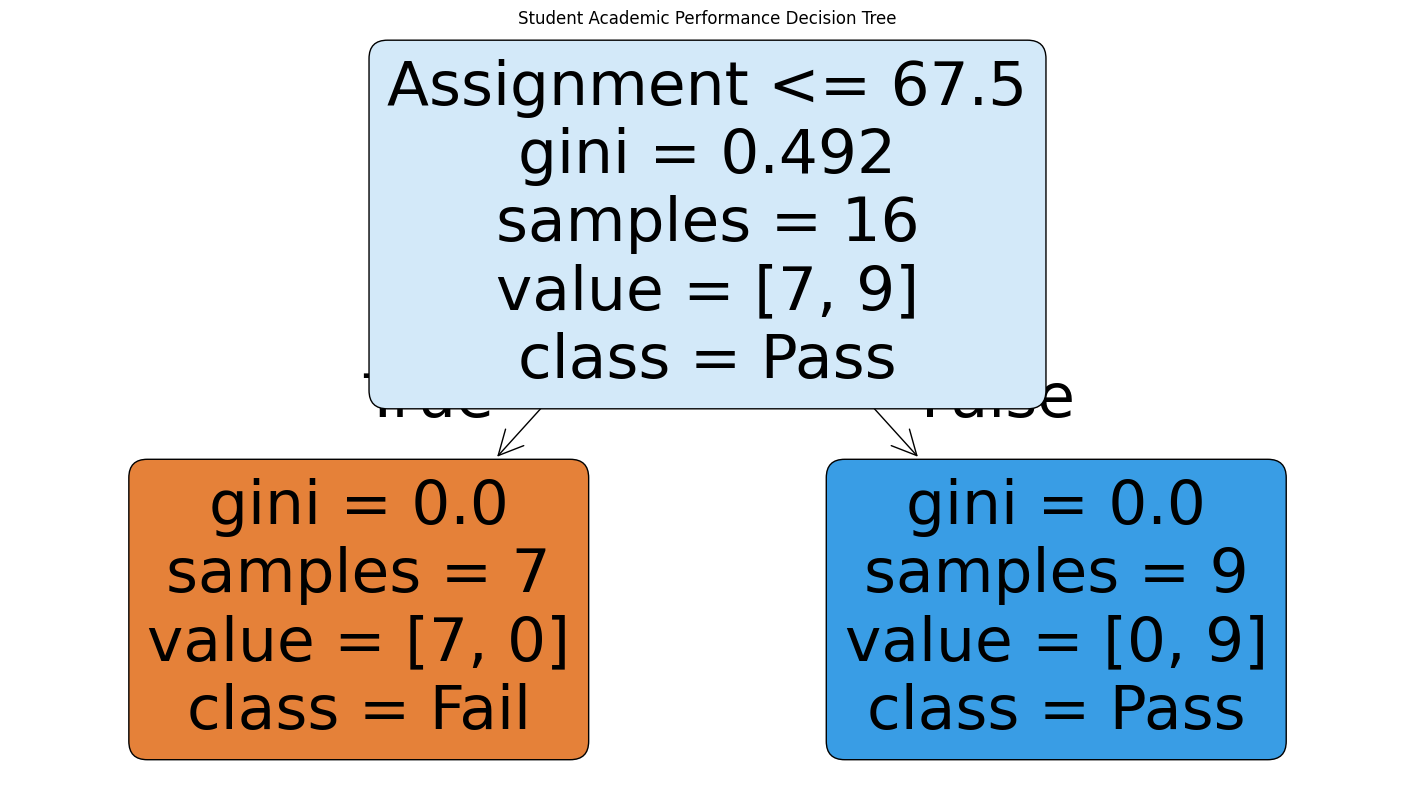

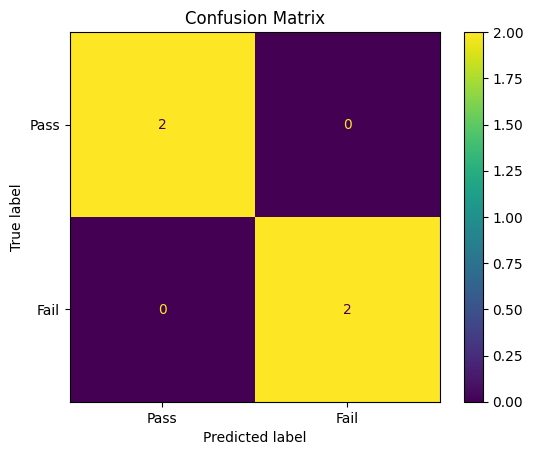

In [1]:

# Assignment 02
# Student Academic Performance Prediction
# Using Decision Tree Classification

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Step 1: Create Dataset

data = {
    'Attendance': [
        90,85,80,75,95,60,55,65,88,50,
        72,58,92,68,78,45,82,62,87,52
    ],

    'Study_Hours': [
        15,12,10,8,18,5,4,6,14,3,
        7,5,16,6,9,2,11,4,13,3
    ],

    'Previous_Marks': [
        85,78,75,70,90,45,40,50,82,35,
        65,48,88,55,72,30,80,42,79,38
    ],

    'Assignment': [
        95,90,85,80,95,50,45,55,90,40,
        75,50,98,60,80,35,85,48,88,42
    ],

    'Participation': [
        5,4,4,3,5,2,1,2,5,1,
        3,2,5,2,4,1,4,2,4,1
    ],

    'Result': [
        'Pass','Pass','Pass','Pass','Pass',
        'Fail','Fail','Fail','Pass','Fail',
        'Pass','Fail','Pass','Fail','Pass',
        'Fail','Pass','Fail','Pass','Fail'
    ]
}

df = pd.DataFrame(data)

# Step 2: Select Features and Target

X = df.drop('Result', axis=1)
y = df['Result']

# Step 3: Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

# Step 4: Create Decision Tree Model

model = DecisionTreeClassifier(random_state=42)

# Step 5: Train the Model

model.fit(X_train, y_train)

# Step 6: Predict Test Results

y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Result': y_test.values,
    'Predicted Result': y_pred
}, index=['S' + str(i+1) for i in y_test.index])

print("\nPrediction Results:")
print(results)

# Step 7: Evaluation Metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label='Pass'
)

recall = recall_score(
    y_test, y_pred, pos_label='Pass'
)

f1 = f1_score(
    y_test, y_pred, pos_label='Pass'
)

cm = confusion_matrix(
    y_test, y_pred, labels=['Pass', 'Fail']
)

print("\nEvaluation Results:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

print("\nConfusion Matrix:")
print(cm)

# Step 8: Identify Root Node

root_feature = X.columns[model.tree_.feature[0]]

print("\nRoot Node:", root_feature)

# Step 9: Feature Importance

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFeature Importance:")
print(importance)

# Step 10: Visualize Decision Tree

plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True
)

plt.title("Student Academic Performance Decision Tree")
plt.show()

# Step 11: Display Confusion Matrix

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Pass', 'Fail']
)

display.plot()
plt.title("Confusion Matrix")
plt.show()
